Árvore de Decisão: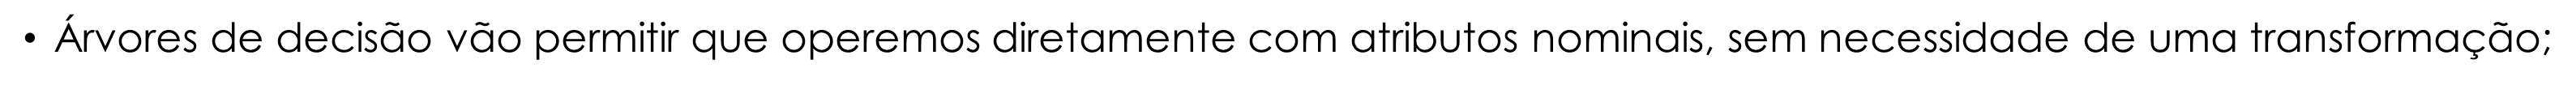
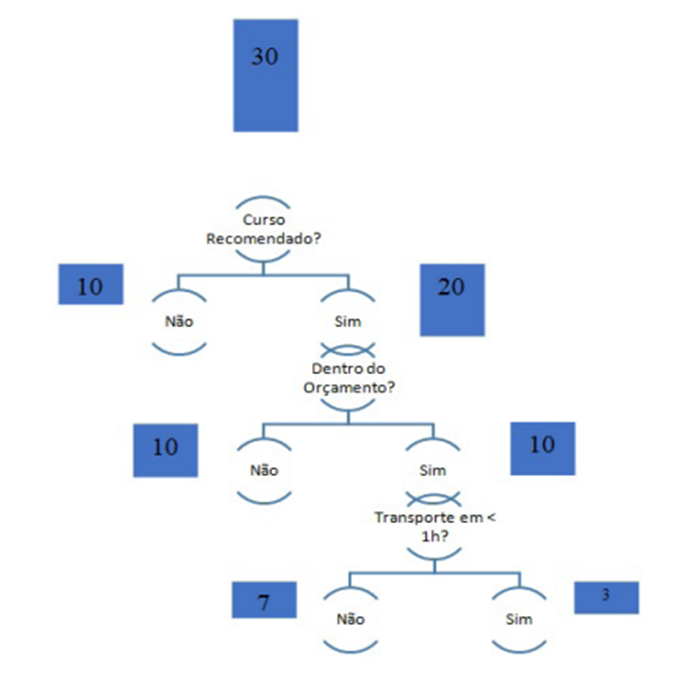

Construindo umja árvore simples
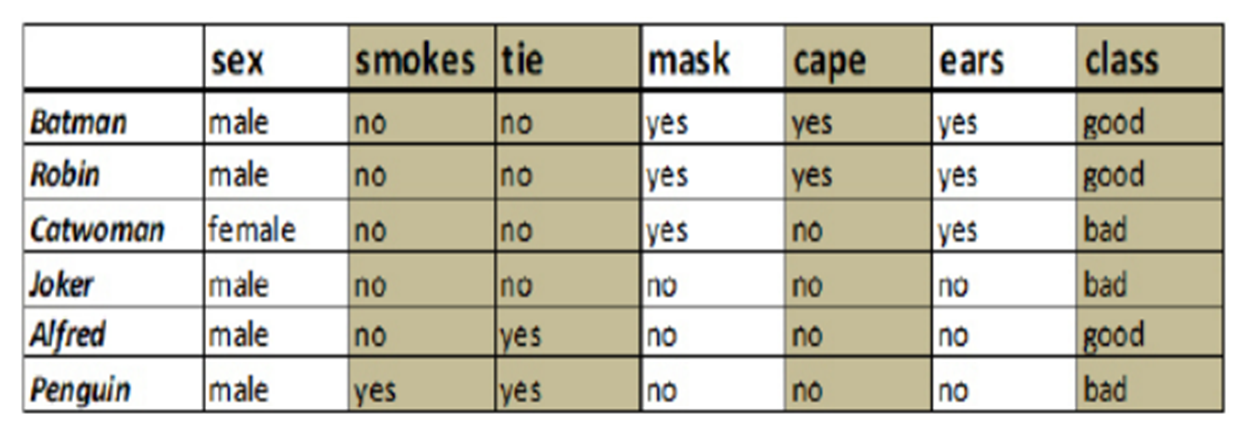

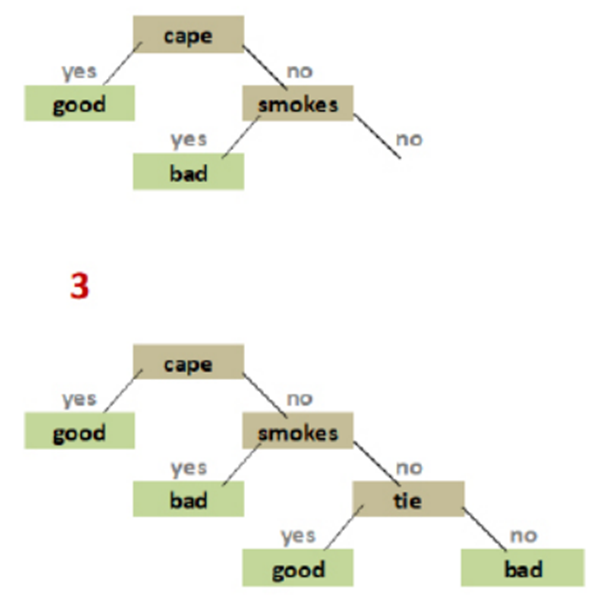

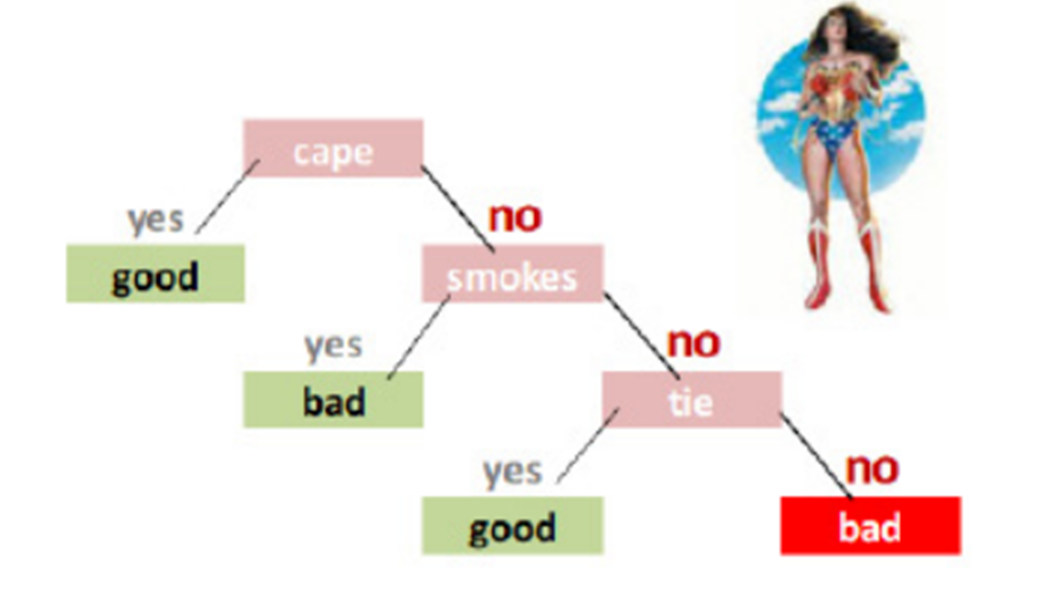

Exemplo de aplicação de árvore de decisão

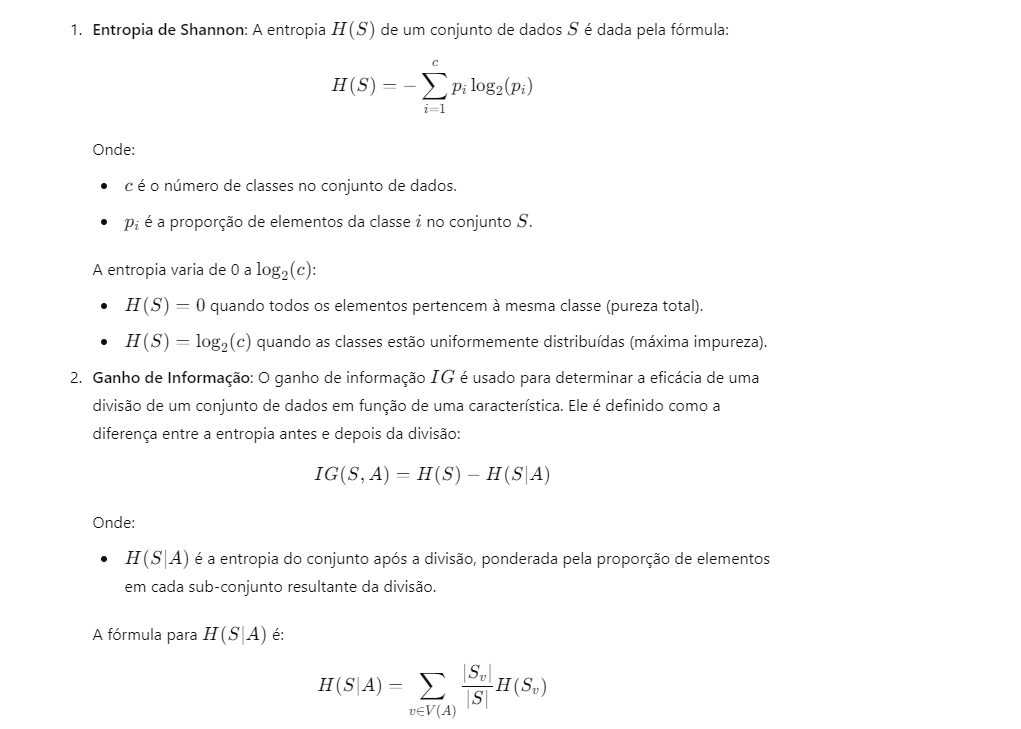
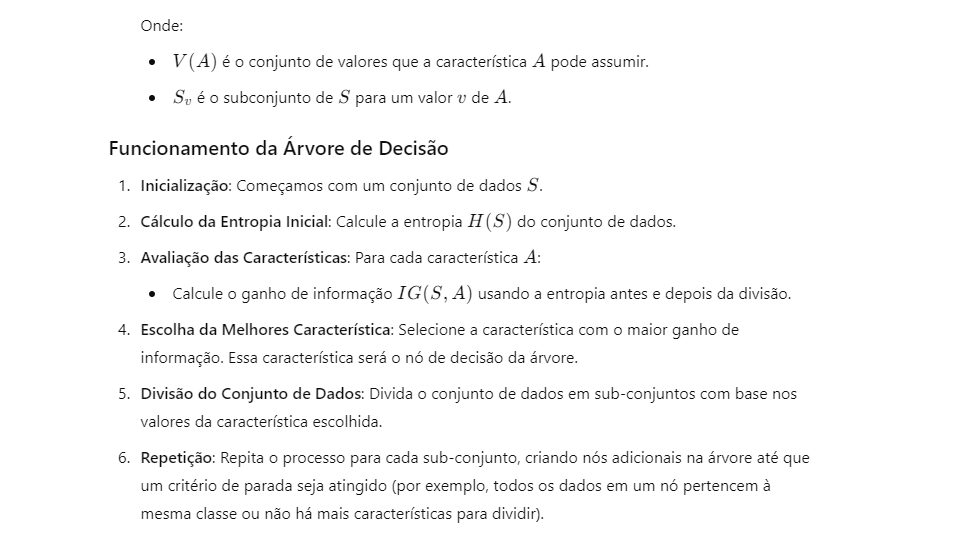

In [ ]:
#Importar as Bibliotecas
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree


In [ ]:
# Carregar o conjunto de dados Iris
iris = datasets.load_iris()
X = iris.data  # Características
y = iris.target  # Rótulos


In [ ]:
# Dividir os dados em conjunto de treinamento e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
# Criar o modelo de árvore de decisão
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)  # Treinar o modelo


DecisionTreeClassifier(random_state=42)

In [ ]:
# Avaliar o modelo
accuracy = clf.score(X_test, y_test)
print(f'Acurácia: {accuracy:.2f}')


Acurácia: 1.00


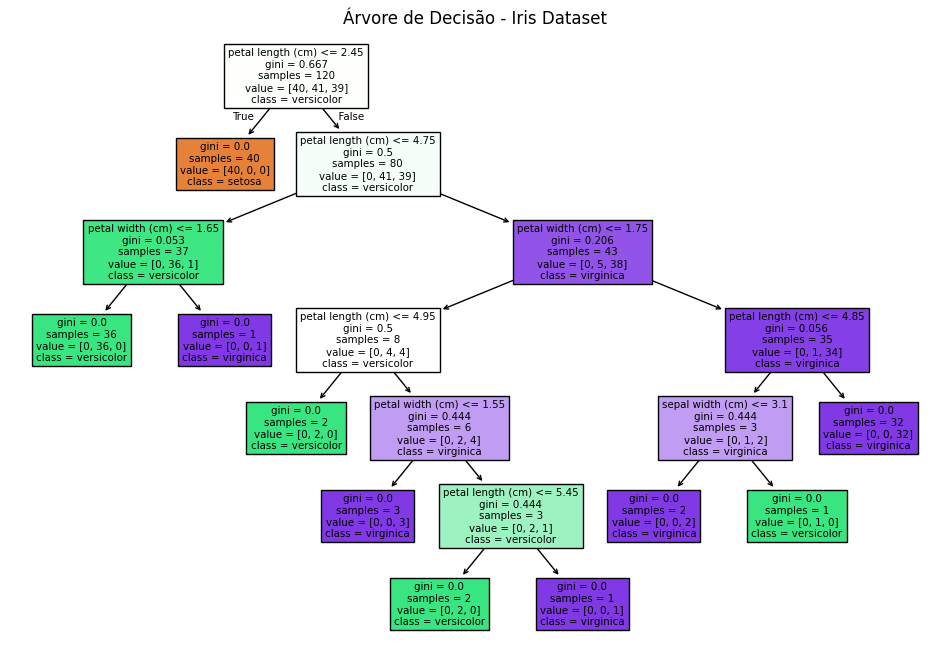

In [ ]:
# Visualizar a árvore de decisão
plt.figure(figsize=(12, 8))
tree.plot_tree(clf, filled=True, feature_names=iris.feature_names, class_names=iris.target_names)
plt.title('Árvore de Decisão - Iris Dataset')
plt.show()


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = clf.predict(X_test)

print("Acurácia:", accuracy_score(y_test, y_pred))
print("Matriz de Confusão:\n", confusion_matrix(y_test, y_pred))
print("Relatório de Classificação:\n", classification_report(y_test, y_pred))


Acurácia: 1.0
Matriz de Confusão:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Relatório de Classificação:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



AGREGAÇÃO DE DADOS E OPERAÇÕES DE GRUPO

Aplicações do groupby

In [ ]:
#Cálculo da Média por Categoria
import pandas as pd

# Criando um DataFrame
data = {
    'categoria': ['A', 'B', 'A', 'B', 'A'],
    'valor': [10, 20, 30, 40, 50]
}
df = pd.DataFrame(data)

# Calculando a média por categoria
media_por_categoria = df.groupby('categoria')['valor'].mean()
print(media_por_categoria)


categoria
A    30.0
B    30.0
Name: valor, dtype: float64


In [ ]:
# Agregando múltiplas funções
agregacao = df.groupby('categoria').agg({'valor': ['sum', 'mean', 'count']})
print(agregacao)


          valor            
            sum  mean count
categoria                  
A            90  30.0     3
B            60  30.0     2


In [ ]:
# Filtrando categorias com média maior que 30
filtro = df.groupby('categoria').filter(lambda x: x['valor'].mean() > 30)
print(filtro)


Empty DataFrame
Columns: [categoria, valor]
Index: []


In [ ]:
# Normalizando os valores dentro de cada categoria
df['valor_normalizado'] = df.groupby('categoria')['valor'].transform(lambda x: (x - x.mean()) / x.std())
print(df)


  categoria  valor  valor_normalizado
0         A     10          -1.000000
1         B     20          -0.707107
2         A     30           0.000000
3         B     40           0.707107
4         A     50           1.000000


In [ ]:
# Calculando a proporção de cada valor em relação à soma total da categoria
df['proporcao'] = df.groupby('categoria')['valor'].transform(lambda x: x / x.sum())
print(df)


  categoria  valor  valor_normalizado  proporcao
0         A     10          -1.000000   0.111111
1         B     20          -0.707107   0.333333
2         A     30           0.000000   0.333333
3         B     40           0.707107   0.666667
4         A     50           1.000000   0.555556


In [ ]:
# Criando uma tabela dinâmica
tabela_dinamica = df.pivot_table(index='categoria', values='valor', aggfunc='sum')
print(tabela_dinamica)


           valor
categoria       
A             90
B             60


In [ ]:
import pandas as pd

# Criando um DataFrame com datas
data = {
    'data': pd.date_range('2023-01-01', periods=6, freq='D'),
    'categoria': ['A', 'B', 'A', 'B', 'A', 'B'],
    'valor': [10, 20, 30, 40, 50, 60]
}
df = pd.DataFrame(data)

# Agrupando por mês e somando apenas a coluna 'valor'
df['mes'] = df['data'].dt.to_period('M')
# Selecting the 'valor' column before applying sum aggregation
resultado = df.groupby('mes')['valor'].sum()
print(resultado)



mes
2023-01    210
Freq: M, Name: valor, dtype: int64


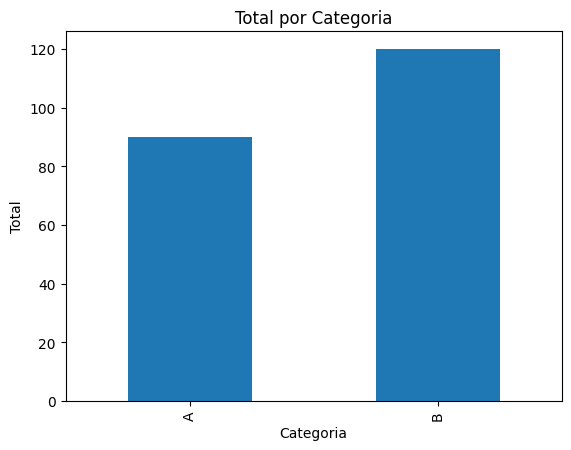

In [ ]:
import matplotlib.pyplot as plt

# Agregando dados
agregacao = df.groupby('categoria')['valor'].sum()

# Visualizando com um gráfico de barras
agregacao.plot(kind='bar')
plt.title('Total por Categoria')
plt.ylabel('Total')
plt.xlabel('Categoria')
plt.show()


In [ ]:
# Contando valores únicos por categoria
contagem_unicos = df.groupby('categoria')['valor'].nunique()
print(contagem_unicos)


categoria
A    3
B    3
Name: valor, dtype: int64


In [ ]:
# Comparando a média e o desvio padrão por categoria
comparacao = df.groupby('categoria').agg({'valor': ['mean', 'std']})
print(comparacao)


          valor      
           mean   std
categoria            
A          30.0  20.0
B          40.0  20.0


In [ ]:
#aplicação de series.rank
import pandas as pd

# Criando um DataFrame
data = {
    'regiao': ['Norte', 'Sul', 'Norte', 'Sul', 'Norte', 'Sul'],
    'vendas': [200, 150, 300, 200, 100, 250]
}
df = pd.DataFrame(data)

# Exibindo o DataFrame
print("DataFrame original:")
print(df)

# Classificando vendas dentro de cada região
df['rank'] = df.groupby('regiao')['vendas'].rank(ascending=False)
print("\nDataFrame com rankings:")
print(df)


DataFrame original:
  regiao  vendas
0  Norte     200
1    Sul     150
2  Norte     300
3    Sul     200
4  Norte     100
5    Sul     250

DataFrame com rankings:
  regiao  vendas  rank
0  Norte     200   2.0
1    Sul     150   3.0
2  Norte     300   1.0
3    Sul     200   2.0
4  Norte     100   3.0
5    Sul     250   1.0


apply() com groupby() para aplicações de estatísticas personalizadas.

In [ ]:
# Cálculo de Estatísticas Personalizadas
import pandas as pd

# Criando um DataFrame
data = {
    'grupo': ['A', 'A', 'B', 'B', 'A', 'B'],
    'valor': [10, 20, 30, 40, 50, 60]
}
df = pd.DataFrame(data)

# Definindo uma função para calcular a soma e a média
def estatisticas(grupo):
    return pd.Series({'soma': grupo.sum(), 'media': grupo.mean()})

# Aplicando a função em cada grupo
resultado = df.groupby('grupo')['valor'].apply(estatisticas)
print(resultado)


grupo       
A      soma      80.000000
       media     26.666667
B      soma     130.000000
       media     43.333333
Name: valor, dtype: float64


In [ ]:
#Normalização de Valores por Grupo
# Função para normalizar
def normalizar(grupo):
    return (grupo - grupo.mean()) / grupo.std()

# Aplicando a normalização e resetando o índice para garantir alinhamento
df['valor_normalizado'] = df.groupby('grupo')['valor'].transform(normalizar)  # Use transform instead of apply
print(df)


  grupo  valor  valor_normalizado
0     A     10          -0.800641
1     A     20          -0.320256
2     B     30          -0.872872
3     B     40          -0.218218
4     A     50           1.120897
5     B     60           1.091089


In [ ]:
#Filtragem com Condições
# Função para verificar se a média é maior que um valor específico
def verificar_media(grupo):
    if grupo.mean() > 30:
        return grupo
    else:
        return pd.Series(dtype='float')  # Retorna uma série vazia

# Aplicando a filtragem
resultado_filtrado = df.groupby('grupo')['valor'].apply(verificar_media)
print(resultado_filtrado)


grupo   
B      2    30
       3    40
       5    60
Name: valor, dtype: int64


<ipython-input-32-4ed7b7e77937>:10: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  resultado_filtrado = df.groupby('grupo')['valor'].apply(verificar_media)


In [ ]:
#Aplicando Funções de Agregação Personalizadas
# Função para calcular múltiplas estatísticas
def resumo(grupo):
    return pd.Series({
        'min': grupo.min(),
        'max': grupo.max(),
        'media': grupo.mean()
    })

# Aplicando a função em cada grupo
resumo_por_grupo = df.groupby('grupo')['valor'].apply(resumo)
print(resumo_por_grupo)


grupo       
A      min      10.000000
       max      50.000000
       media    26.666667
B      min      30.000000
       max      60.000000
       media    43.333333
Name: valor, dtype: float64


In [ ]:
#Aplicando Funções de Numpy
import numpy as np

# Função para calcular a variância
def variancia(grupo):
    return np.var(grupo)

# Aplicando a variância em cada grupo
variancia_por_grupo = df.groupby('grupo')['valor'].apply(variancia)
print(variancia_por_grupo)


grupo
A    288.888889
B    155.555556
Name: valor, dtype: float64


crosstab() no pandas:

In [ ]:
#Contagem de Frequências
import pandas as pd

# Criando um DataFrame
data = {
    'sexo': ['M', 'F', 'M', 'F', 'M', 'F'],
    'status': ['solteiro', 'casado', 'casado', 'solteiro', 'solteiro', 'casado']
}
df = pd.DataFrame(data)

# Criando uma tabela de contingência
tabela_contingencia = pd.crosstab(df['sexo'], df['status'])
print(tabela_contingencia)


status  casado  solteiro
sexo                    
F            2         1
M            1         2


In [ ]:
# Proporções Relativas
# Tabela de contingência com proporções
proporcao_tabela = pd.crosstab(df['sexo'], df['status'], normalize='all')
print(proporcao_tabela)


status    casado  solteiro
sexo                      
F       0.333333  0.166667
M       0.166667  0.333333


In [ ]:
#Análise de Dados com Variáveis Adicionais
# Criando um DataFrame com uma variável adicional
data = {
    'sexo': ['M', 'F', 'M', 'F', 'M', 'F', 'M', 'F'],
    'status': ['solteiro', 'casado', 'casado', 'solteiro', 'solteiro', 'casado', 'solteiro', 'casado'],
    'idade': [25, 30, 35, 28, 22, 40, 29, 34]
}
df = pd.DataFrame(data)

# Criando uma tabela de contingência com idade como coluna
tabela_idade = pd.crosstab(df['sexo'], df['status'], margins=True)
print(tabela_idade)


status  casado  solteiro  All
sexo                         
F            3         1    4
M            1         3    4
All          4         4    8


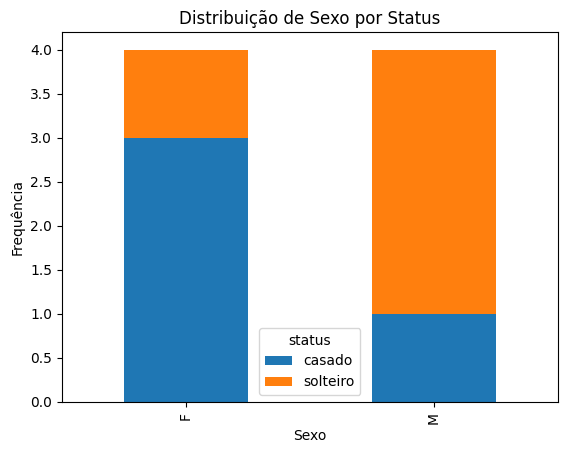

In [ ]:
#Visualização de Dados com Gráficos
import matplotlib.pyplot as plt

# Criando uma tabela de contingência
tabela_contingencia = pd.crosstab(df['sexo'], df['status'])

# Criando um gráfico de barras
tabela_contingencia.plot(kind='bar', stacked=True)
plt.title('Distribuição de Sexo por Status')
plt.xlabel('Sexo')
plt.ylabel('Frequência')
plt.show()


In [ ]:
#Análise de Testes Estatísticos
from scipy.stats import chi2_contingency

# Criando uma tabela de contingência
tabela = pd.crosstab(df['sexo'], df['status'])

# Realizando o teste qui-quadrado
chi2, p, dof, expected = chi2_contingency(tabela)
print(f"Chi2: {chi2}, p-valor: {p}")


Chi2: 0.5, p-valor: 0.47950012218695337
